# **Monitoramento Automatizado de Obras via Visão Computacional**

**Projeto Acadêmico:** Classificação de Fases de Construção com YOLOv8


**Aluno:** Carlos Frederico Coelho Lisboa

**Fases Monitoradas:** Fundação, Alvenaria, Cobertura e Revestimento Externo.

 1. **Módulo de Gestão de Dados e Curadoria**

Este módulo é destinado à preparação do ambiente e garantia de que os dados brutos estão íntegros antes de qualquer processamento.

  **1.1. Conexão e Setup**

Montamos o Google Drive para acessar o dataset e definimos as variáveis de ambiente que guiarão o fluxo de trabalho.

In [2]:
import os
from google.colab import drive

# Montando o Google Drive
drive.mount('/content/drive')

# Definição do caminho base
PATH_DATASET_BRUTO = "/content/drive/MyDrive/Trabalho - Visão Computacional/Dataset_Bruto"

# Verificação de existência
if os.path.exists(PATH_DATASET_BRUTO):
    print(f"✅ Conexão estabelecida com sucesso!")
    print(f"Diretório: {PATH_DATASET_BRUTO}")
else:
    print("❌ Erro: Caminho não encontrado. Verifique o nome da pasta no seu Drive.")

Mounted at /content/drive
✅ Conexão estabelecida com sucesso!
Diretório: /content/drive/MyDrive/Trabalho - Visão Computacional/Dataset_Bruto


**1.2. Inspeção de Dados**

Antes de treinar, precisamos entender a distribuição das classes e validar visualmente se as imagens estão corretamente rotuladas nas subpastas.

Classe: Fundação | Total de imagens: 50
Classe: Alvenaria | Total de imagens: 68
Classe: Cobertura | Total de imagens: 71
Classe: Revestimento Externo | Total de imagens: 77


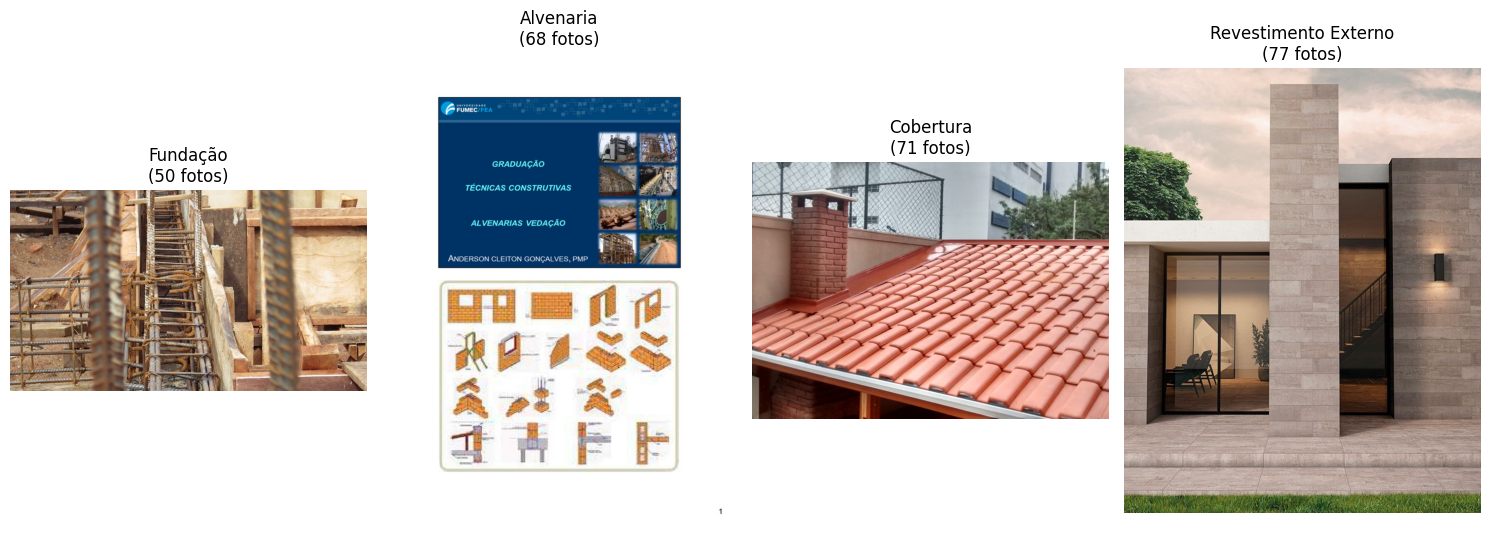

In [3]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import glob

classes = ['Fundação', 'Alvenaria', 'Cobertura', 'Revestimento Externo']

def inspecionar_dataset(path):
    plt.figure(figsize=(15, 8))
    total_encontradas = 0
    for i, classe in enumerate(classes):
        pasta_classe = os.path.join(path, classe)
        imagens = glob.glob(f"{pasta_classe}/*.jpg") + glob.glob(f"{pasta_classe}/*.png")+ glob.glob(f"{pasta_classe}/*.jpeg")

        print(f"Classe: {classe} | Total de imagens: {len(imagens)}")
        total_encontradas += len(imagens)

        if imagens:
            img = Image.open(imagens[0])
            plt.subplot(1, 4, i + 1)
            plt.imshow(img)
            # Evita SyntaxError com \n dentro de f-string (Python < 3.12)
            titulo = classe + "\n(" + str(len(imagens)) + " fotos)"
            plt.title(titulo)
            plt.axis('off')

    if total_encontradas == 0:
        print("Nenhuma imagem encontrada. Verifique o PATH_DATASET_BRUTO.")
    plt.tight_layout()
    plt.show()

inspecionar_dataset(PATH_DATASET_BRUTO)


**1.3. Data Augmentation (Albumentations)**

Para aumentar a robustez do modelo frente a variações climáticas e de iluminação comuns em canteiros de obras, aplicaremos transformações sintéticas.

In [7]:
import os
import glob
import cv2
import numpy as np
import albumentations as A
from tqdm import tqdm
import shutil # Import shutil for directory operations

classes = ['Fundação', 'Alvenaria', 'Cobertura', 'Revestimento Externo']

# Definição da Pipeline de Augmentation
# blur_limit como tupla (mín, máx) para compatibilidade com albumentations >= 1.x
transform = A.Compose([
    A.RandomBrightnessContrast(p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomGamma(p=0.3),
    A.Blur(blur_limit=(3, 3), p=0.2),
    A.CLAHE(p=0.2)  # Melhora o contraste em fotos com muita sombra
])

PATH_TREINO_LOCAL = "/content/dataset_processado"

# Clean up the directory before starting to ensure no corrupted old files remain
if os.path.exists(PATH_TREINO_LOCAL):
    shutil.rmtree(PATH_TREINO_LOCAL)
os.makedirs(PATH_TREINO_LOCAL, exist_ok=True)

def processar_e_aumentar(path_origem, path_destino):
    for classe in classes:
        origem = os.path.join(path_origem, classe)
        destino = os.path.join(path_destino, classe)
        os.makedirs(destino, exist_ok=True)

        imagens = glob.glob(f"{origem}/*.jpg") + glob.glob(f"{origem}/*.png")+ glob.glob(f"{origem}/*.jpeg")
        print(f"Processando {classe} ({len(imagens)} imagens)...")

        for img_path in tqdm(imagens):
            image = cv2.imread(img_path)

            # BUG FIX: verifica se a imagem foi carregada corretamente
            if image is None:
                print(f"⚠️  Não foi possível carregar a imagem original: {img_path} — pulando.")
                continue

            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Salva a original
            filename = os.path.basename(img_path)
            original_dest_path = os.path.join(destino, filename)
            cv2.imwrite(original_dest_path, cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR))
            # New check: Verify integrity of the saved original image
            if cv2.imread(original_dest_path) is None:
                print(f"❌ Imagem original salva corrompida: {original_dest_path} — deletando.")
                os.remove(original_dest_path)
                continue

            # Gera 2 variações aumentadas
            for j in range(2):
                augmented = transform(image=image_rgb)['image']
                aug_dest_path = os.path.join(destino, f"aug_{j}_{filename}")
                cv2.imwrite(aug_dest_path, cv2.cvtColor(augmented, cv2.COLOR_RGB2BGR))
                # New check: Verify integrity of the saved augmented image
                if cv2.imread(aug_dest_path) is None:
                    print(f"❌ Imagem aumentada salva corrompida: {aug_dest_path} — deletando.")
                    os.remove(aug_dest_path)
                    continue

processar_e_aumentar(PATH_DATASET_BRUTO, PATH_TREINO_LOCAL)

Processando Fundação (50 imagens)...


100%|██████████| 50/50 [00:02<00:00, 17.68it/s]


Processando Alvenaria (68 imagens)...


100%|██████████| 68/68 [00:02<00:00, 27.60it/s]


Processando Cobertura (71 imagens)...


100%|██████████| 71/71 [00:03<00:00, 18.10it/s]


Processando Revestimento Externo (77 imagens)...


100%|██████████| 77/77 [00:04<00:00, 16.53it/s]


**1.4. Treinamento do Modelo**

 O treinamento requer GPU ativa e tempo considerável de processamento. O modelo final já foi pré-treinado e será carregado no módulo seguinte.

In [8]:
import matplotlib
import shutil
import os

# Limpar o cache de fontes do Matplotlib para resolver o erro 'Can not load face'
# Isso evita problemas com fontes que podem ter sido corrompidas ou não carregadas corretamente
if os.path.exists(matplotlib.get_cachedir()):
    shutil.rmtree(matplotlib.get_cachedir())
    print("✅ Cache de fontes do Matplotlib limpo com sucesso.")


!pip install ultralytics -q
from ultralytics import YOLO

# Inicializando o modelo YOLOv8 Nano para Classificação
model = YOLO('yolov8n-cls.pt')

# project e name tornam o caminho do best.pt sempre previsível:
# /content/runs/classify/train_obras/weights/best.pt
model.train(
    data=PATH_TREINO_LOCAL,
    epochs=50,
    imgsz=224,
    project='/content/runs/classify',
    name='train',
    exist_ok=True    # evita criar train2, train3... ao re-treinar
)

Ultralytics 8.4.42 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_processado, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a11b47f70e0>
curves: []
curves_results: []
fitness: 1.0
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 1.0, 'metrics/accuracy_top5': 1.0, 'fitness': 1.0}
save_dir: PosixPath('/content/runs/classify/train')
speed: {'preprocess': 0.10672076767897623, 'inference': 1.0760251582491134, 'loss': 0.0003319696971516733, 'postprocess': 0.0004313872076106698}
top1: 1.0
top5: 1.0

In [9]:
import os

model_weights_path = '/content/runs/classify/train/weights'

print(f"Verificando o conteúdo de: {model_weights_path}")

files = []

if os.path.exists(model_weights_path):
    files = os.listdir(model_weights_path)
    if files:
        print("Arquivos encontrados:")
        for f in files:
            print(f"- {f}")
        if 'best.pt' in files:
            print("O arquivo best.pt foi encontrado!")
            print(f"Caminho: {os.path.join(model_weights_path, 'best.pt')}")
        else:
            print("best.pt nao foi encontrado na pasta weights.")
    else:
        print("A pasta weights esta vazia.")
else:
    print("O diretorio especificado nao existe. O treinamento pode ter falhado.")

if 'best.pt' not in files:
    print("Procurando por best.pt em outras pastas de treinamento...")
    found_path = None
    for root, dirs, dir_files in os.walk('/content/runs/classify'):
        if 'best.pt' in dir_files:
            found_path = os.path.join(root, 'best.pt')
            break
    if found_path:
        print(f"best.pt encontrado em: {found_path}")
        print("Atualize MODEL_PATH na celula de carregamento com este caminho.")
    else:
        print("best.pt nao foi encontrado. Verifique o log do treinamento.")


Verificando o conteúdo de: /content/runs/classify/train/weights
Arquivos encontrados:
- best.pt
- last.pt
O arquivo best.pt foi encontrado!
Caminho: /content/runs/classify/train/weights/best.pt


**2. Módulo de Avaliação**

Este módulo permite testar a eficácia do modelo treinado através de uma interface interativa.


**2.1. Carregamento do Modelo**

Aqui baixamos os pesos treinados (best.pt) que representam a inteligência do nosso sistema.

In [10]:
from ultralytics import YOLO
import os

# O modelo 'best.pt' foi encontrado localmente após o treinamento.
# Usaremos o caminho direto para carregá-lo.
MODEL_PATH = '/content/runs/classify/train/weights/best.pt'

if os.path.exists(MODEL_PATH):
    print(f"✅ Carregando o modelo do caminho local: {MODEL_PATH}")
    model = YOLO(MODEL_PATH)
    print("✅ Modelo carregado com sucesso!")
else:
    print(f"❌ Erro: O arquivo do modelo não foi encontrado em {MODEL_PATH}. Por favor, verifique o caminho ou execute o treinamento novamente.")

✅ Carregando o modelo do caminho local: /content/runs/classify/train/weights/best.pt
✅ Modelo carregado com sucesso!


**2.2. Interface Streamlit (app.py)**

O código abaixo gera o aplicativo que servirá de interface.

In [11]:
%%writefile app.py
import streamlit as st
from ultralytics import YOLO
from PIL import Image
import numpy as np
import requests
from io import BytesIO

st.set_page_config(page_title="IA de Monitoramento de Obras", layout="wide")

st.title("🏗️ Classificador de Fases de Obra")
st.write("Sistema de Visão Computacional para Loteamentos")

@st.cache_resource
def load_model():
    return YOLO('best.pt')

model = load_model()

# Sidebar para upload
uploaded_file = st.sidebar.file_uploader("Envie uma foto da obra", type=['jpg', 'png', 'jpeg'])

# Imagens de Teste Rápido
st.sidebar.markdown("---")
st.sidebar.write("### Teste Rápido")
test_imgs = {
    "Exemplo Fundação": "https://images.unsplash.com/photo-1541888946425-d81bb19480c5?q=80&w=500",
    "Exemplo Alvenaria": "https://images.unsplash.com/photo-1584622650111-993a426fbf0a?q=80&w=500",
    "Exemplo Cobertura": "https://images.unsplash.com/photo-1632759145351-1d592919f522?q=80&w=500"
}

selection = st.sidebar.selectbox("Escolha um exemplo:", ["Nenhum"] + list(test_imgs.keys()))

image = None
if uploaded_file:
    image = Image.open(uploaded_file).convert("RGB")
elif selection != "Nenhum":
    # BUG FIX: faz download da URL e abre como PIL Image
    # (YOLO aceita PIL Image; st.image também)
    try:
        response = requests.get(test_imgs[selection], timeout=10)
        response.raise_for_status()
        image = Image.open(BytesIO(response.content)).convert("RGB")
    except Exception as e:
        st.error(f"Não foi possível carregar a imagem de exemplo: {e}")

if image:
    col1, col2 = st.columns(2)

    with col1:
        # BUG FIX: use_column_width depreciado — substituído por use_container_width
        st.image(image, caption="Imagem Analisada", use_container_width=True)

    # Predição
    results = model(image)
    names_dict = results[0].names
    probs = results[0].probs.data.tolist()

    with col2:
        st.write("### Resultados da Predição")
        res_dict = {names_dict[i]: probs[i] for i in range(len(names_dict))}
        st.bar_chart(res_dict)

        # BUG FIX: cast explícito para int garante chave válida no dicionário
        classe_dominante = names_dict[int(np.argmax(probs))]
        st.success(f"Fase Identificada: **{classe_dominante}**")


Writing app.py


**2.3. Túnel de Acesso**

Para visualizar a interface acima, execute os comandos abaixo.

*Instruções:*

a - Execute a célula abaixo.

b - Clique no link do localtunnel (URL terminando em .loca.lt).

c - No campo "Endpoint IP", insira o número IP que aparecerá no output da célula (obtido pelo comando curl).

In [13]:
# Instalando dependencias da interface
!pip install streamlit ultralytics -q

# Instala o cloudflared (tunel da Cloudflare, sem conta, sem token)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

import subprocess
import threading
import time
import re

# Inicia o Streamlit em background
def run_streamlit():
    subprocess.Popen(
        ["streamlit", "run", "app.py", "--server.port", "8501",
         "--server.headless", "true",
         "--server.enableCORS", "false",
         "--server.enableXsrfProtection", "false"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )

thread = threading.Thread(target=run_streamlit, daemon=True)
thread.start()
time.sleep(5)
print("Streamlit iniciado.")

# Inicia o tunel cloudflared e captura a URL publica
tunnel = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

# Le o output ate encontrar a URL (tryhackme.trycloudflare.com)
print("Aguardando URL do tunel...")
for line in tunnel.stderr:
    decoded = line.decode("utf-8", errors="ignore")
    match = re.search(r'https://[\w\-]+\.trycloudflare\.com', decoded)
    if match:
        print(f"Interface disponivel em: {match.group(0)}")
        break


cloudflared: Text file busy
Streamlit iniciado.
Aguardando URL do tunel...
Interface disponivel em: https://les-peace-andale-prayer.trycloudflare.com
